# Week 2 - End-to-End VisionPort Architecture

## Objective

To understand the architecture of an end-to-end deep learning
inference system and analyse the interaction between its major
components.

## Core Components

- FastAPI: API layer responsible for receiving and handling
  inference requests.
- Triton Inference Server: Manages model inference execution
  and inference requests.
- TensorRT: Optimizes model execution for NVIDIA GPUs.
- Deep Learning Model: Performs object detection on input images.
- GPU: Executes accelerated tensor computations.
- Client: Submits input data and receives inference results.

## Learning Outcomes

- Identify the purpose of each architectural component.
- Understand the inference request flow.
- Analyse the dependencies between the API, inference server,
  model, optimization engine and GPU.
- Understand how a failure in one component affects the system.

## Component Analysis

### 1. FastAPI

FastAPI acts as the interface between the client and the
inference system.

Responsibilities:

- Receive HTTP requests.
- Validate input.
- Accept image data.
- Forward requests to the inference backend.
- Return results to the client.

### 2. Triton Inference Server

Triton manages the model-serving layer.

Responsibilities:

- Load model artifacts.
- Manage inference requests.
- Support concurrent requests.
- Manage model execution configurations.
- Provide inference-serving capabilities.

### 3. TensorRT

TensorRT is an NVIDIA inference optimization SDK.

Responsibilities:

- Optimize deep learning computation graphs.
- Optimize execution for NVIDIA GPU hardware.
- Support reduced precision inference.
- Improve inference efficiency.

### 4. Detection Model

The detection model receives image tensors and generates
predictions such as:

- Vehicle categories
- Bounding-box coordinates
- Confidence scores

### 5. GPU

The GPU executes computationally intensive model operations
using parallel processing.

### 6. Client

The client submits images and receives the inference results.

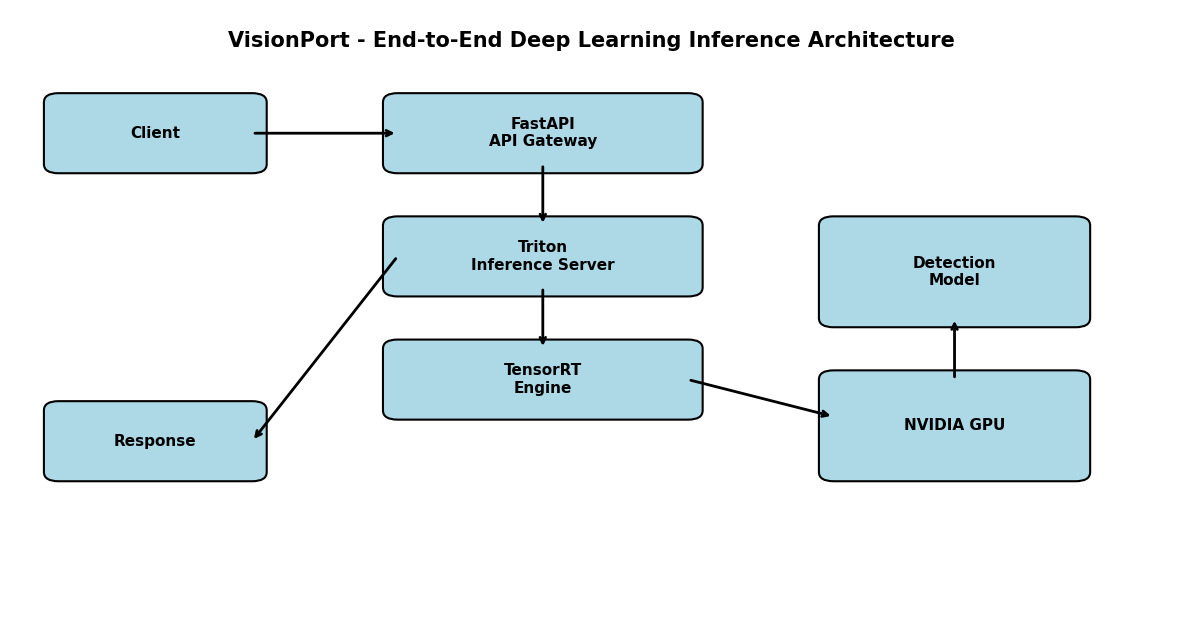

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(15, 8))

ax.set_xlim(0, 12)
ax.set_ylim(0, 10)
ax.axis("off")

components = {
    "Client": (0.5, 7.5, 2, 1),
    "FastAPI\nAPI Gateway": (4, 7.5, 3, 1),
    "Triton\nInference Server": (4, 5.5, 3, 1),
    "TensorRT\nEngine": (4, 3.5, 3, 1),
    "Detection\nModel": (8.5, 5, 2.5, 1.5),
    "NVIDIA GPU": (8.5, 2.5, 2.5, 1.5),
    "Response": (0.5, 2.5, 2, 1)
}

for name, (x, y, w, h) in components.items():

    box = FancyBboxPatch(
        (x, y),
        w,
        h,
        boxstyle="round,pad=0.15",
        linewidth=1.5,
        edgecolor="black",
        facecolor="lightblue"
    )

    ax.add_patch(box)

    ax.text(
        x + w/2,
        y + h/2,
        name,
        ha="center",
        va="center",
        fontsize=11,
        weight="bold"
    )

def arrow(start, end):
    ax.annotate(
        "",
        xy=end,
        xytext=start,
        arrowprops=dict(
            arrowstyle="->",
            lw=2,
            color="black"
        )
    )

arrow((2.5, 8), (4, 8))
arrow((5.5, 7.5), (5.5, 6.5))
arrow((5.5, 5.5), (5.5, 4.5))
arrow((7, 4), (8.5, 3.4))
arrow((9.75, 4), (9.75, 5))
arrow((4, 6), (2.5, 3))

ax.text(
    6,
    9.4,
    "VisionPort - End-to-End Deep Learning Inference Architecture",
    ha="center",
    fontsize=15,
    weight="bold"
)

plt.show()

## End-to-End Inference Request Flow

### Step 1 - Client Request

The client submits an image to the inference system.

### Step 2 - FastAPI

FastAPI receives the request, validates the input and prepares
the request for the inference backend.

### Step 3 - Triton Inference Server

Triton receives the inference request and manages model execution.

### Step 4 - TensorRT

The TensorRT engine optimizes model execution for the target
NVIDIA GPU.

### Step 5 - GPU Execution

The GPU executes the model's computational operations.

### Step 6 - Detection Model

The model processes the input image and produces predictions.

### Step 7 - Postprocessing

The predictions are converted into usable detection results,
including object classes, bounding boxes and confidence scores.

### Step 8 - Response

The results are returned to the client.

---

Client
  ↓
FastAPI
  ↓
Triton Inference Server
  ↓
TensorRT Engine
  ↓
GPU Model Execution
  ↓
Detection Output
  ↓
Response

In [ ]:
import pandas as pd

dependencies = pd.DataFrame({
    "Component": [
        "Client",
        "FastAPI",
        "Triton",
        "TensorRT",
        "Detection Model",
        "GPU"
    ],

    "Depends On": [
        "API endpoint",
        "Inference backend",
        "Model configuration and backend",
        "Compatible model and GPU",
        "Input tensors and execution environment",
        "Compatible hardware and drivers"
    ],

    "Failure Impact": [
        "Requests cannot be submitted",
        "Requests cannot enter the inference system",
        "Model serving becomes unavailable",
        "Optimized execution may fail",
        "Detection results cannot be generated",
        "GPU acceleration becomes unavailable"
    ]
})

display(dependencies)

,Component,Depends On,Failure Impact
0,Client,API endpoint,Requests cannot be submitted
1,FastAPI,Inference backend,Requests cannot enter the inference system
2,Triton,Model configuration and backend,Model serving becomes unavailable
3,TensorRT,Compatible model and GPU,Optimized execution may fail
4,Detection Model,Input tensors and execution environment,Detection results cannot be generated
5,GPU,Compatible hardware and drivers,GPU acceleration becomes unavailable


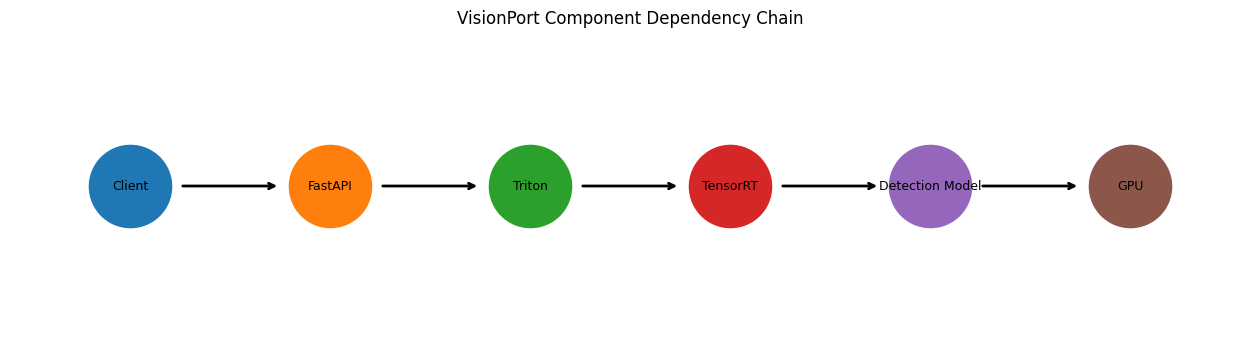

In [ ]:
import matplotlib.pyplot as plt

components = [
    "Client",
    "FastAPI",
    "Triton",
    "TensorRT",
    "Detection Model",
    "GPU"
]

dependencies = [
    ("Client", "FastAPI"),
    ("FastAPI", "Triton"),
    ("Triton", "TensorRT"),
    ("TensorRT", "Detection Model"),
    ("Detection Model", "GPU")
]

positions = {
    "Client": (0, 0),
    "FastAPI": (1, 0),
    "Triton": (2, 0),
    "TensorRT": (3, 0),
    "Detection Model": (4, 0),
    "GPU": (5, 0)
}

fig, ax = plt.subplots(figsize=(16, 4))

ax.axis("off")

for component, (x, y) in positions.items():

    ax.scatter(x, y, s=3500)

    ax.text(
        x,
        y,
        component,
        ha="center",
        va="center",
        fontsize=9
    )

for source, target in dependencies:

    x1, y1 = positions[source]
    x2, y2 = positions[target]

    ax.annotate(
        "",
        xy=(x2 - 0.25, y2),
        xytext=(x1 + 0.25, y1),
        arrowprops=dict(
            arrowstyle="->",
            lw=2
        )
    )

ax.set_xlim(-0.6, 5.6)
ax.set_ylim(-1, 1)

plt.title("VisionPort Component Dependency Chain")
plt.show()

## Component Dependency Analysis

### FastAPI Dependency

FastAPI depends on the availability of the inference backend.

If the inference backend is unavailable, the API cannot produce
valid model inference responses.

### Triton Dependency

Triton requires a valid model configuration and a compatible
inference backend.

Incorrect model configuration or unavailable model artifacts
can prevent model serving.

### TensorRT Dependency

TensorRT requires compatible model artifacts and GPU hardware
support.

Engine compatibility depends on hardware, software versions
and configuration.

### Model Dependency

The model requires correctly formatted input tensors and
a compatible inference environment.

### GPU Dependency

GPU execution depends on compatible NVIDIA hardware,
drivers and software configuration.

### Conclusion

The inference system is a dependency-driven architecture.
The failure or incompatibility of a critical component can
affect the availability or performance of the complete
inference pipeline.

# Week 2 Conclusion

This week, the architecture of an end-to-end deep learning
inference system was explored.

The system consists of a client, API layer, inference server,
optimized model execution engine, deep learning model and GPU.

FastAPI manages incoming requests, Triton manages inference
serving, TensorRT optimizes model execution, and the GPU
provides hardware acceleration.

The components depend on each other through the inference
pipeline. Understanding these dependencies is essential for
debugging, optimization and deployment of deep learning systems.

## Completed Topics

- End-to-end inference architecture
- FastAPI
- Triton Inference Server
- TensorRT
- Detection model
- GPU execution
- Inference request flow
- Component dependency analysis